In [1]:
import numpy as np
import joblib
import importlib
import matplotlib.pyplot as plt
import os 
import pickle
import bayes_logistic as bl
from collections import defaultdict
import warnings
warnings.filterwarnings("ignore")
from tqdm import trange

In [2]:
os.chdir('/Users/eochoa/Documents/Research_Abuj/ASD/Code/')

In [3]:
import pandas as pd
from utils import *
from logistic_utils import *
from GP_utils import *
from linear_utils import *
import expt_utils as expt_utils
from sklearn.preprocessing import normalize
from sklearn.datasets import load_iris
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.mixture import GaussianMixture
from sklearn.mixture import BayesianGaussianMixture
from scipy.special import expit, logit
import sklearn
import seaborn as sns
# importlib.reload(expt_utils)
from sklearn.neighbors import NearestNeighbors

from sklearn.metrics import pairwise_distances

In [4]:
algos_log_dict = {
  'Random': [logistic_solver, {}, 10, 'Random', 'g'],
  'IDS': [IDS_logistic, {"M": 1000}, 10, 'IDS', 'm'],
  'TS': [TS_logistic, {}, 10, 'TS', 'b'],
  'UCB': [UCB_logistic, {}, 10, 'UCB', 'y'],
  # 'Random': [graph_solver, {}, 10, 'Random', '-sm']
}

In [5]:
algos_GP_dict = {
  'Random': [GP_solver, {}, 10, 'Random', 'g'],
  'TS': [TS_logistic, {}, 10, 'TS', 'm'],
  #'TS_GP': [TS_GP, {}, 10, 'TS', 'r'],
  'TS_GP_GM': [TS_GP_GM, {}, 10, 'TS_GP_GM', 'b'],
  'TS_Dist_GP_GM': [TS_Dist_GP_GM, {}, 10, 'TS_Dist_GP_GM', 'y'],
  'TS_GP_Rand': [TS_GP_Rand, {}, 10, 'TS_GP_Rand', 'c'],
  'TS_GP_True': [TS_GP_True, {}, 10, 'TS_GP_True', 'r']
  #'UCB': [UCB_logistic, {}, 10, 'UCB', 'y'],
  # 'Random': [graph_solver, {}, 10, 'Random', '-sm']
}

In [6]:
hsi_df = pd.read_csv('/Users/eochoa/Downloads/GHISACONUS_2008_001_speclib.csv', skiprows=6)
hsi_df_filter = hsi_df.query('Image == "EO1H0440332012234110KD_SGS_01"')#.reset_index(drop=True)
hsi_df_filter['Crop_num'] = (hsi_df['Crop'] == 'rice') * 1
df_desc = hsi_df_filter.loc[:, ['long','lat','X803', 'X1629', 'X2174']].reset_index(drop=True)
df_yield = hsi_df_filter.loc[:, ['Crop_num']].reset_index(drop=True)

idx = np.random.choice(99,99,replace=False)
df_desc = df_desc.iloc[idx,:].reset_index(drop=True)
df_yield = df_yield.iloc[idx].reset_index(drop=True)


In [7]:
n_row, n_col = df_yield.shape
_, n_desc =  df_desc.shape
cutoff = n_desc
T = n_row
prob_log_dict = {
    "m": n_row,
    "noise": 0.01,
    "d": cutoff
  }
prob_log = logistic_discover(**prob_log_dict)

x = df_desc.to_numpy()
x = x[:, :cutoff]
x = normalize(x, axis=0, norm='l2')
prob_log.x = x
prob_log.y = df_yield.iloc[:, 0].values #/ 100.0

prob_GP_dict = {
    "m": n_row,
    "noise": 0.01,
    "d": cutoff
  }
prob_GP = GP_discover(**prob_GP_dict)
x = df_desc.to_numpy()
x = x[:, :cutoff]
x = normalize(x, axis=0, norm='l2')
prob_GP.x = x
prob_GP.y = df_yield.iloc[:, 0].values #/ 100.0

<AxesSubplot: >

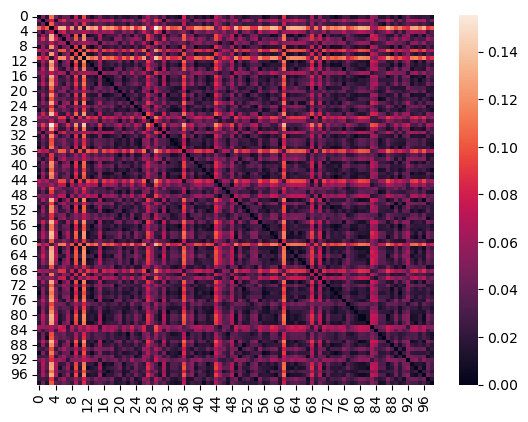

In [8]:
D = pairwise_distances(x)
sns.heatmap(D)

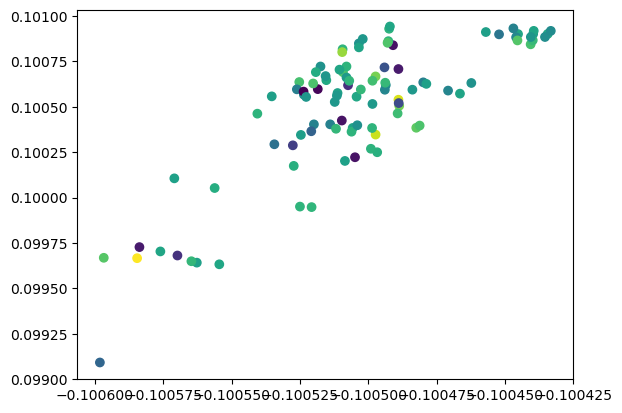

In [9]:
y = np.random.rand(99)
neigh = NearestNeighbors(radius=0.02).fit(x)
nn = neigh.radius_neighbors(x, return_distance=False)
y_nn = np.zeros(99)
for i in range(99):
    y_nn[i] = y[nn[i]].mean()
plt.scatter(x[:,0], x[:,1], c=y_nn)

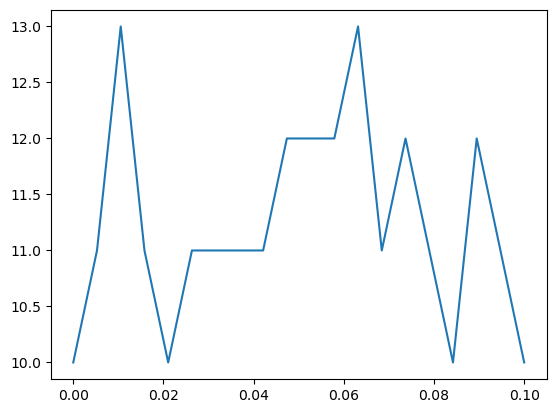

In [10]:
max_regret = np.zeros(20)
r_list = np.linspace(0,.1,20)
for i, r in enumerate(r_list):
    solver_2 = TS_GP_Rand(prob_GP, r = r)#, **algo_params)
    max_regret[i] = solver_2.run(T=T, M=0)[0].max()
    
plt.plot(r_list, max_regret)

In [11]:
algos_dict = {
  'Random': [GP_solver, {}, 10, 'Random', 'g'],
  'TS_logistic': [TS_logistic, {}, 10, 'TS_logistic', 'r'],
  'TS_GP': [TS_GP, {}, 10, 'TS_GP', 'r'],
  'TS_GP_True': [TS_GP_True, {}, 10, 'TS_GP_True', 'y'],
  #'TS_GP_GM': [TS_GP_GM, {}, 10, 'TS_GP_GM', 'b'],
  #'TS_Dist_GP_GM': [TS_Dist_GP_GM, {}, 10, 'TS_Dist_GP_GM', 'y'],
  'TS_GP_Rand_2': [TS_GP_Rand, {'r':.06}, 10, 'TS_GP_Rand r = 0.06', 'c'],
  'TS_GP_Rand': [TS_GP_Rand, {}, 10, 'TS_GP_Rand', 'b'],
  'Multi_G_GP': [Multi_G_GP, {}, 10, 'Multi_G_GP', 'y'],
  'G_logistic': [G_logistic, {}, 10, 'G_logistic', 'm'],
  'G_logistic_2': [G_logistic, {'r':.08}, 10, 'G_logistic = 0.07', 'm']
  #'UCB': [UCB_logistic, {}, 10, 'UCB', 'y'],
  # 'Random': [graph_solver, {}, 10, 'Random', '-sm']
}

In [13]:
reg_list = {algo:[] for algo in algos_dict}
#tau_list = {algo:[] for algo in algos_dict}

for trial_idx in trange(10):
    t_prob = deepcopy(prob_GP)
    # print(prob.x)
    for algo, algo_setup in algos_dict.items():
        algo_func, algo_params, algo_N_trials, _, _ = algo_setup
                # print(algo_func)
        if not trial_idx < algo_N_trials:
            continue
        solver = algo_func(t_prob, **algo_params)
        reg, _ = solver.run(T)[:2]
        #act_list[algo].append(getattr(solver, "logistic_discover"))
        #act_list[algo].append(t_prob.actions)
        # print(prob.rewards)
        reg_list[algo].append(reg)
        #tau_list[algo].append(tau)

100%|███████████████████████████████████████████| 10/10 [04:01<00:00, 24.11s/it]


In [16]:
T

99

In [17]:
solver = Multi_G_GP(t_prob)
solver.run(T, M=60)

(array([ 0,  0,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
         1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
         1,  1,  1,  2,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  4,
         5,  5,  6,  6,  6,  6,  7,  7,  8,  9, 10, 10, 10, 11, 11, 11, 10,
        10, 10, 10,  9,  8,  8,  7,  7,  6,  6,  5,  4,  4,  4,  4,  3,  3,
         2,  2,  2,  2,  2,  1,  1,  1,  1,  1,  1,  0,  0,  0]),
 [1,
  1,
  0,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  0,
  0,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  0,
  0,
  1,
  0,
  1,
  1,
  1,
  0,
  1,
  0,
  0,
  0,
  1,
  1,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  1,
  1,
  0,
  1,
  0,
  1,
  0,
  1,
  1,
  0,
  0,
  0,
  1,
  0,
  1,
  0,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  0,
  0,
  1,
  0,
  0],
 78)

In [18]:
60 / 78

0.7692307692307693

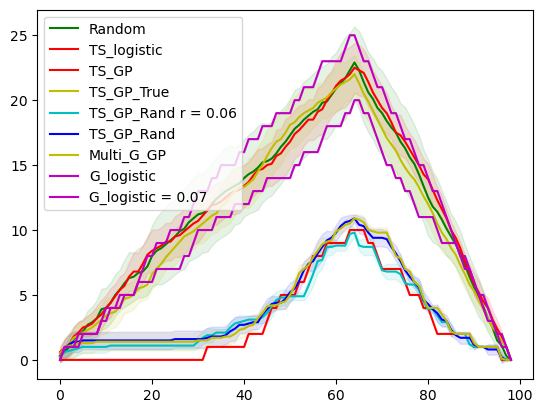

In [14]:
for algo in algos_dict:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y = np.mean(reg_list[algo], axis = 0)[:T]
    ci = np.std(reg_list[algo], axis = 0)[:T]
    plt.plot(range(T), y,
                  "-"+algo_style, label=algo_label)
    plt.fill_between(range(T), (y-ci), (y+ci), color = algo_style, alpha=.1)

    plt.legend()

In [44]:
S = 10
res_log_G = defaultdict(list)
res_log_TS = defaultdict(list)
res_log_Rand = defaultdict(list)
res_GP_G = defaultdict(list)
res_GP_G_nn = defaultdict(list)
res_GP_Multi_G = defaultdict(list)


for M in trange(1,66):
    taus_G = np.zeros(S)
    taus_TS = np.zeros(S)
    taus_Rand = np.zeros(S)
    
    taus_GP_G = np.zeros(S)
    taus_GP_G_nn = np.zeros(S)
    taus_Multi_GP_G = np.zeros(S)
    for i in range(S):
        solver = TS_logistic(prob_log)#, **algo_params)
        _, _, taus_TS[i] = solver.run(T=T, M=M)
        
        solver = G_logistic(prob_log, r = 0.08)#, **algo_params)
        _, _, taus_G[i] = solver.run(T=T, M=M)
        
        solver = TS_GP_Rand(prob_GP)#, **algo_params)
        _, _, taus_GP_G[i] = solver.run(T=T, M=M)
        
        solver = TS_GP_Rand(prob_GP, 0.06)#, **algo_params)
        _, _, taus_GP_G_nn[i] = solver.run(T=T, M=M)
        
        solver = Multi_G_GP(prob_GP)#, **algo_params)
        _, _, taus_Multi_GP_G[i] = solver.run(T=T, M=M)

        solver = logistic_solver(prob_log)#, **algo_params)
        _, _, taus_Rand[i] = solver.run(T=T, M=M)
        
    res_log_TS['M'].append(M)
    res_log_TS['tau'].append(taus_TS.mean())
    res_log_TS['regret'].append(taus_TS.mean())
    
    res_log_G['M'].append(M)
    res_log_G['tau'].append(taus_G.mean())
    
    res_log_Rand['M'].append(M)
    res_log_Rand['tau'].append(taus_Rand.mean())
    
    res_GP_G['M'].append(M)
    res_GP_G['tau'].append(taus_GP_G.mean())
    
    res_GP_G_nn['M'].append(M)
    res_GP_G_nn['tau'].append(taus_GP_G_nn.mean())
    
    res_GP_Multi_G['M'].append(M)
    res_GP_Multi_G['tau'].append(taus_Multi_GP_G.mean())

100%|███████████████████████████████████████████| 65/65 [24:46<00:00, 22.87s/it]


In [45]:
res_log_TS_df = pd.DataFrame(res_log_TS)
res_log_TS_df['M / E[tau]'] = res_log_TS_df['M'] / (res_log_TS_df['tau']+1)

res_log_G_df = pd.DataFrame(res_log_G)
res_log_G_df['M / E[tau]'] = res_log_G_df['M'] / (res_log_G_df['tau']+1)

res_log_Rand_df = pd.DataFrame(res_log_Rand)
res_log_Rand_df['M / E[tau]'] = res_log_Rand_df['M'] / (res_log_Rand_df['tau']+1)

res_GP_G_df = pd.DataFrame(res_GP_G)
res_GP_G_df['M / E[tau]'] = res_GP_G_df['M'] / (res_GP_G_df['tau']+1)

res_GP_G_nn_df = pd.DataFrame(res_GP_G_nn)
res_GP_G_nn_df['M / E[tau]'] = res_GP_G_nn_df['M'] / (res_GP_G_nn_df['tau']+1)

res_GP_Multi_G_df = pd.DataFrame(res_GP_Multi_G)
res_GP_Multi_G_df['M / E[tau]'] = res_GP_Multi_G_df['M'] / (res_GP_Multi_G_df['tau']+1)

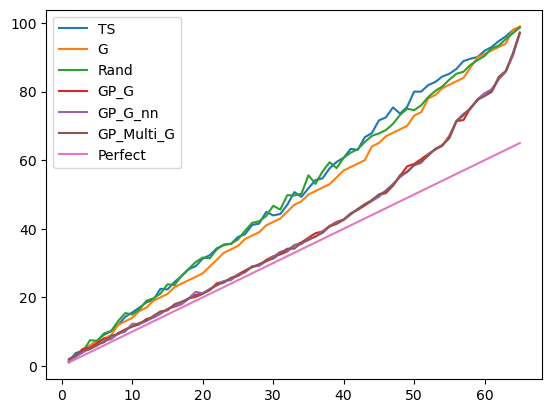

In [46]:
plt.plot(res_log_TS_df['M'], res_log_TS_df['tau']+1, label='TS')
plt.plot(res_log_G_df['M'], res_log_G_df['tau']+1, label='G')
plt.plot(res_log_Rand_df['M'], res_log_Rand_df['tau']+1, label='Rand')
plt.plot(res_GP_G_df['M'], res_GP_G_df['tau']+1, label='GP_G')
plt.plot(res_GP_G_nn_df['M'], res_GP_G_nn_df['tau']+1, label='GP_G_nn')
plt.plot(res_GP_Multi_G_df['M'], res_GP_Multi_G_df['tau']+1, label='GP_Multi_G')
plt.plot(res_log_TS_df['M'], res_log_TS_df['M'], label='Perfect')
plt.legend()

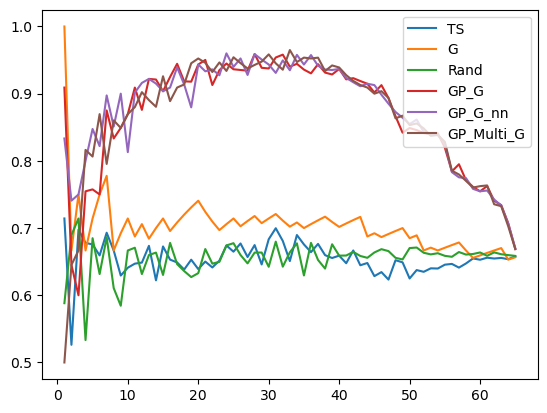

In [47]:
plt.plot(res_log_TS_df['M'], res_log_TS_df['M / E[tau]'], label='TS')
plt.plot(res_log_G_df['M'], res_log_G_df['M / E[tau]'], label='G')
plt.plot(res_log_Rand_df['M'], res_log_Rand_df['M / E[tau]'], label='Rand')
plt.plot(res_GP_G_df['M'], res_GP_G_df['M / E[tau]'], label='GP_G')

plt.plot(res_GP_G_nn_df['M'], res_GP_G_nn_df['M / E[tau]'], label='GP_G_nn')
plt.plot(res_GP_Multi_G_df['M'], res_GP_Multi_G_df['M / E[tau]'], label='GP_Multi_G')

plt.legend()